# Market Regime Detection and ML-Driven Dynamic Asset Allocation

## Initial Report and Exploratory Data Analysis

### Table of Contents
1. Business Problem 
2. Research Question
3. Dataset Overview
4. Data Quality Assessment
5. Exploratory Data Analysis
6. Feature Engineering
7. Baseline Machine Learning Model
8. Conclusion and Next Steps 

## 1. Business Problem 

Traditional portfolio allocation approaches rely heavily on historical relationships between asset classes and may struggle to adapt to changing market conditions. This project investigates whether market regimes can be identified using machine learning techniques and whether these insights can support dynamic asset allocation decisions.

## 2. Research Question

Can market regime detection and machine learning techniques improve dynamic asset allocation compared to traditional static allocation approaches?

## 3. Dataset Overview

- SPY  (US Equity) 
- QQQ  (Technology)
- TLT  (Treasury Bonds)
- GLD  (Gold)
- VNQ  (Real Estate)
- HYG  (High Yield Bonds)

These represent a multi-asset portfolio and are easy to download with yfinance.

In [99]:
!pip install yfinance --upgrade

Defaulting to user installation because normal site-packages is not writeable
  Attempting uninstall: yfinance
    Found existing installation: yfinance 1.7.0
    Uninstalling yfinance-1.7.0:
      Successfully uninstalled yfinance-1.7.0


In [131]:
import yfinance as yf
import pandas as pd
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier


In [101]:
import sys
print(sys.executable)

C:\ProgramData\anaconda3\python.exe


In [102]:
!pip --version

pip 25.3 from C:\ProgramData\anaconda3\Lib\site-packages\pip (python 3.13)



In [104]:
print(yf.__version__)

1.7.0


In [105]:

tickers = ['SPY', 'QQQ', 'TLT', 'GLD', 'VNQ', 'HYG']

data = yf.download(
    tickers,
    start='2015-01-01',
    auto_adjust=True
)

data.head()

[*********************100%***********************]  6 of 6 completed


Price            Close                                               \
Ticker             GLD        HYG        QQQ         SPY        TLT   
Date                                                                  
2015-01-02  114.080002  48.073097  94.462692  169.267502  91.935226   
2015-01-05  115.800003  47.627781  93.077049  166.210632  93.379410   
2015-01-06  117.120003  47.445343  91.829071  164.645081  95.061821   
2015-01-07  116.430000  47.740467  93.012833  166.696762  94.874100   
2015-01-08  115.940002  48.099930  94.793091  169.654785  93.617683   

Price                        High                                    ...  \
Ticker            VNQ         GLD        HYG        QQQ         SPY  ...   
Date                                                                 ...   
2015-01-02  51.642830  114.800003  48.250153  95.618924  170.462264  ...   
2015-01-05  51.925480  116.000000  47.879951  94.159874  168.394140  ...   
2015-01-06  52.440521  117.500000  47.729703  93.370721  167.034580  ...   
2015-01-07  53.244522  116.879997  47.901424  93.233066  167.034592  ...   
2015-01-08  53.445496  116.870003  48.196505  94.976618  169.869025  ...   

Price            Open                                      Volume           \
Ticker            QQQ         SPY        TLT        VNQ       GLD      HYG   
Date                                                                         
2015-01-02  95.215163  170.050280  91.191485  51.316212   7109600  3271900   
2015-01-05  94.049754  168.229349  92.433476  51.504650   8177400  7523100   
2015-01-06  93.214722  166.515476  94.375847  51.975725  11238300  9489700   
2015-01-07  92.434717  165.963432  94.375863  52.641541   6434200  8353100   
2015-01-08  93.802029  168.097488  94.130365  53.608804   7033700  8388600   

Price                                               
Ticker           QQQ        SPY       TLT      VNQ  
Date                                                
2015-01-02  31314600  121465900   9432000  5570500  
2015-01-05  36521300  169632600   9789500  6073700  
2015-01-06  66205500  209151400  18331300  7577100  
2015-01-07  37577400  125346700   9762900  6920700  
2015-01-08  40212600  147217800   8055300  5255000  

[5 rows x 30 columns]

## 4. Data Quality Assessment

In [106]:
type(data)

pandas.core.frame.DataFrame

In [107]:
data.columns

MultiIndex([( 'Close', 'GLD'),
            ( 'Close', 'HYG'),
            ( 'Close', 'QQQ'),
            ( 'Close', 'SPY'),
            ( 'Close', 'TLT'),
            ( 'Close', 'VNQ'),
            (  'High', 'GLD'),
            (  'High', 'HYG'),
            (  'High', 'QQQ'),
            (  'High', 'SPY'),
            (  'High', 'TLT'),
            (  'High', 'VNQ'),
            (   'Low', 'GLD'),
            (   'Low', 'HYG'),
            (   'Low', 'QQQ'),
            (   'Low', 'SPY'),
            (   'Low', 'TLT'),
            (   'Low', 'VNQ'),
            (  'Open', 'GLD'),
            (  'Open', 'HYG'),
            (  'Open', 'QQQ'),
            (  'Open', 'SPY'),
            (  'Open', 'TLT'),
            (  'Open', 'VNQ'),
            ('Volume', 'GLD'),
            ('Volume', 'HYG'),
            ('Volume', 'QQQ'),
            ('Volume', 'SPY'),
            ('Volume', 'TLT'),
            ('Volume', 'VNQ')],
           names=['Price', 'Ticker'])

In [110]:
prices = data['Close']
prices.head()

Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Date,,,,,,
2015-01-02,114.080002,48.073097,94.462692,169.267502,91.935226,51.642830
2015-01-05,115.800003,47.627781,93.077049,166.210632,93.379410,51.925480
2015-01-06,117.120003,47.445343,91.829071,164.645081,95.061821,52.440521
2015-01-07,116.430000,47.740467,93.012833,166.696762,94.874100,53.244522
2015-01-08,115.940002,48.099930,94.793091,169.654785,93.617683,53.445496


In [111]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2977 entries, 2015-01-02 to 2026-11-03
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     2977 non-null   float64
 1   HYG     2977 non-null   float64
 2   QQQ     2977 non-null   float64
 3   SPY     2977 non-null   float64
 4   TLT     2977 non-null   float64
 5   VNQ     2977 non-null   float64
dtypes: float64(6)
memory usage: 162.8 KB


In [130]:
prices.shape

(2977, 6)

In [114]:
prices.isnull().sum().sum()

np.int64(0)

**Interpretation from missing value analysis** : 
- No missing values in the dataset.
- No immediate data cleaning is required.
- All six ETF time series share the same trading calendar.
- We can proceed directly to exploratory analysis and feature engineering.

### Data Quality Assessment Summary

The dataset contains daily adjusted closing prices for six ETFs representing multiple asset classes: equities (SPY, QQQ), fixed income (TLT, HYG), commodities (GLD), and real estate (VNQ). The dataset consists of 2,973 observations spanning January 2015 through October 2026. All variables are numeric and no missing values were identified, indicating the data is suitable for further analysis and feature engineering.

- 2,973 daily observations
- 6 ETF assets
- Dataset spans multiple market environments, including:
    - COVID-19 market crash (2020)
    - Post-COVID recovery
    - Inflation and interest rate hikes (2022)
    - Recent market conditions
- All six variables are numerical (float64)
- No obvious datatype issues
- All ETFs have the same number of observations
- No missing values are immediately visible

## 5. Exploratory Data Analysis

### 5.1 Price Trend Analysis

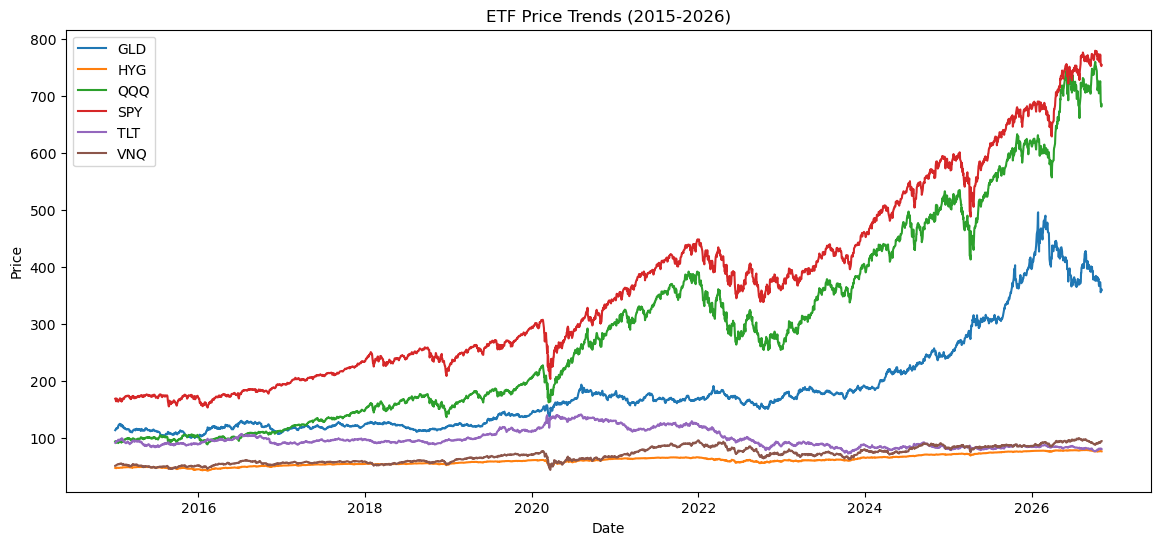

In [132]:
plt.figure(figsize=(14,6))

for col in prices.columns:
    plt.plot(prices.index, prices[col], label=col)

plt.title('ETF Price Trends (2015-2026)')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.show()

<font size="3"> The above chart compares raw prices, which is a slightly misleading because each ETF started at a different price level. For better EDA visualization will have to create a normalized performance chart, where all assets start at 100.

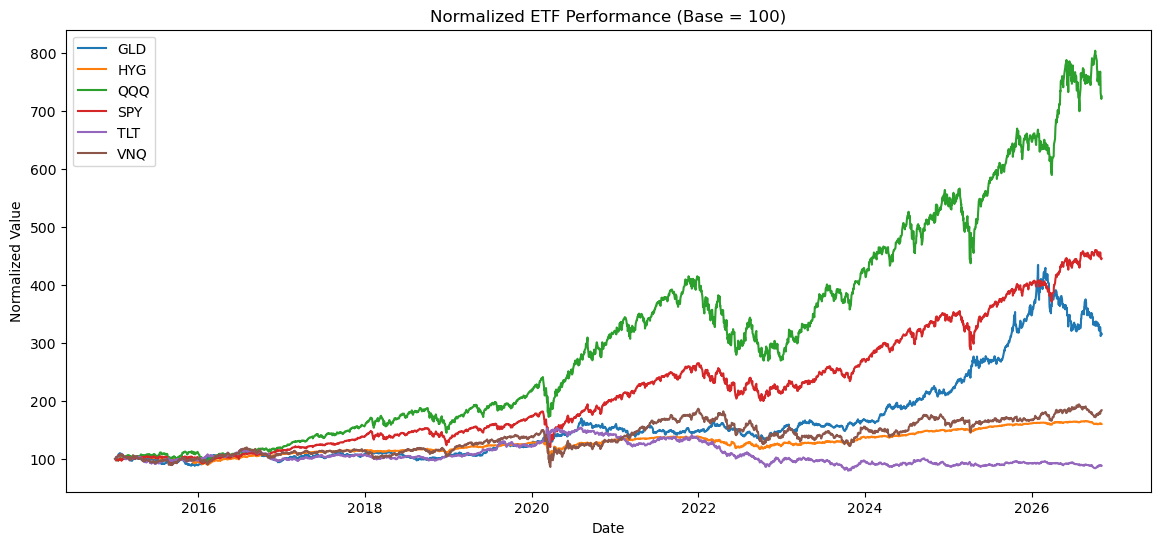

In [116]:
normalized_prices = prices / prices.iloc[0] * 100

plt.figure(figsize=(14,6))

for col in normalized_prices.columns:
    plt.plot(
        normalized_prices.index,
        normalized_prices[col],
        label=col
    )

plt.title('Normalized ETF Performance (Base = 100)')
plt.xlabel('Date')
plt.ylabel('Normalized Value')
plt.legend()
plt.show()

### Price Trend Analysis Summary
#### 1. QQQ was the Best Performing Asset
QQQ grew from a base value of 100 to approximately 750-800.
This significantly outperformed all other asset classes.
Technology stocks delivered the strongest cumulative returns during the analysis period.
#### 2. SPY Delivered Strong Long-Term Growth
SPY increased from approximately 100 to roughly 450.
While it underperformed QQQ, it substantially outperformed bonds and credit assets.
This reflects the strong performance of the broader U.S. equity market over the period.
#### 3. GLD Provided Strong Performance in Recent Years
Gold remained relatively flat for several years before accelerating sharply after 2023.
This behavior suggests GLD may provide diversification benefits during periods of market uncertainty and inflation concerns.
#### 4. TLT Underperformed Significantly
Treasury bonds (TLT) experienced a prolonged decline following the 2021-2022 rate hiking cycle.
TLT is the only asset that ended the period below its initial normalized value.
This highlights the impact of rising interest rates on long-duration bonds.
#### 5. HYG and VNQ Produced Moderate Returns
HYG remained relatively stable with modest growth.
VNQ produced better returns than HYG but significantly lagged equities.
#### 6. Evidence of Distinct Market Regimes

Several periods are visually apparent:
- Pre-COVID bull market (2015-2019)
- COVID crash (2020)
- Post-pandemic recovery (2020-2021)
- Inflation and rising-rate environment (2022)
- Recent growth and market transition period (2023-2026)


### 5.2 Calculate Daily Returns 

In [117]:
returns = prices.pct_change()

returns.head()


Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Date,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,0.015077,-0.009263,-0.014669,-0.018059,0.015709,0.005473
2015-01-06,0.011399,-0.003830,-0.013408,-0.009419,0.018017,0.009919
2015-01-07,-0.005891,0.006220,0.012891,0.012461,-0.001975,0.015332
2015-01-08,-0.004209,0.007530,0.019140,0.017745,-0.013243,0.003775


In [118]:
print(returns.shape)
returns.tail()

(2977, 6)


Ticker,GLD,HYG,QQQ,SPY,TLT,VNQ
Date,,,,,,
2026-10-28,0.003304,-0.000129,0.006045,0.003443,-0.007840,-0.006494
2026-10-29,-0.013226,-0.000129,-0.014154,-0.003820,0.006174,0.022660
2026-10-30,-0.034702,-0.001934,-0.034739,-0.017729,0.004295,0.000746
2026-11-02,0.016499,-0.006974,-0.013613,-0.004790,-0.001344,0.011922
2026-11-03,-0.006609,0.001171,0.006152,0.002992,-0.007586,-0.000526


<font size="3">  A review of missing values confirmed that the dataset is complete. Therefore, the returns DataFrame should only exhibit NaN values in the first row, as there is no prior observation available for the initial return calculation.

In [119]:
returns.isnull().sum()

Ticker
GLD    1
HYG    1
QQQ    1
SPY    1
TLT    1
VNQ    1
dtype: int64

In [120]:
returns = returns.dropna()
returns.isnull().sum().sum()

np.int64(0)

In [121]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
GLD,2976.0,4.384960e-04,0.010276,-0.102742,-0.004880,0.000557,0.005610,0.063587
HYG,2976.0,1.711702e-04,0.005091,-0.054966,-0.001782,0.000237,0.002189,0.065459
QQQ,2976.0,7.613851e-04,0.013795,-0.119788,-0.005127,0.001212,0.007864,0.120031
SPY,2976.0,5.631109e-04,0.011018,-0.109424,-0.003711,0.000612,0.005916,0.105019
TLT,2976.0,9.454772e-07,0.009281,-0.066683,-0.005605,0.000322,0.005458,0.075196
VNQ,2976.0,2.861108e-04,0.012683,-0.177278,-0.005706,0.000652,0.006946,0.089967


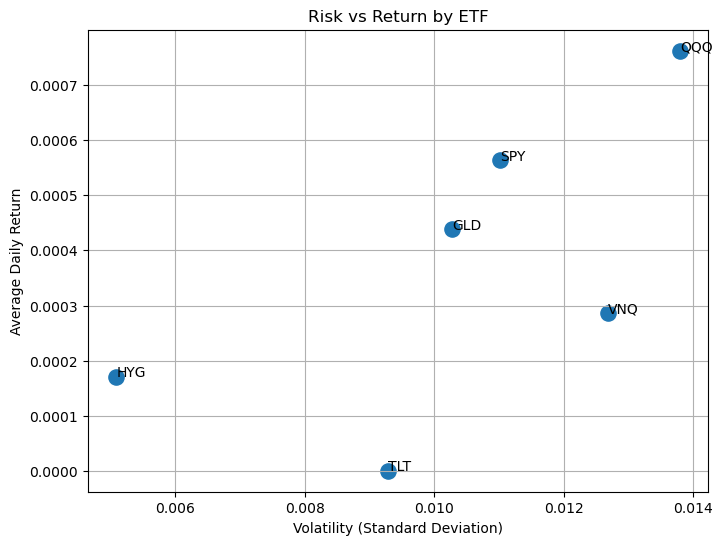

In [133]:
risk_return = returns.describe().T[['mean', 'std']]

plt.figure(figsize=(8,6))

plt.scatter(
    risk_return['std'],
    risk_return['mean'],
    s=120
)

for ticker in risk_return.index:
    plt.annotate(
        ticker,
        (risk_return.loc[ticker, 'std'],
         risk_return.loc[ticker, 'mean'])
    )

plt.title('Risk vs Return by ETF')
plt.xlabel('Volatility (Standard Deviation)')
plt.ylabel('Average Daily Return')
plt.grid(True)

plt.show()

### Daily Return Statistics Summary

- QQQ delivered the highest average daily return but also exhibited the greatest volatility.
- SPY provided strong returns with lower volatility than QQQ.
- HYG demonstrated the lowest volatility among the analyzed assets but also generated relatively modest returns.
- TLT produced near-zero average returns over the study period, reflecting challenges faced by long-term bonds in a rising interest rate environment.

<font size="3"> The variation in risk and return profiles across assets highlights the importance of diversification in portfolio construction.

### 5.3 Correlation Analysis

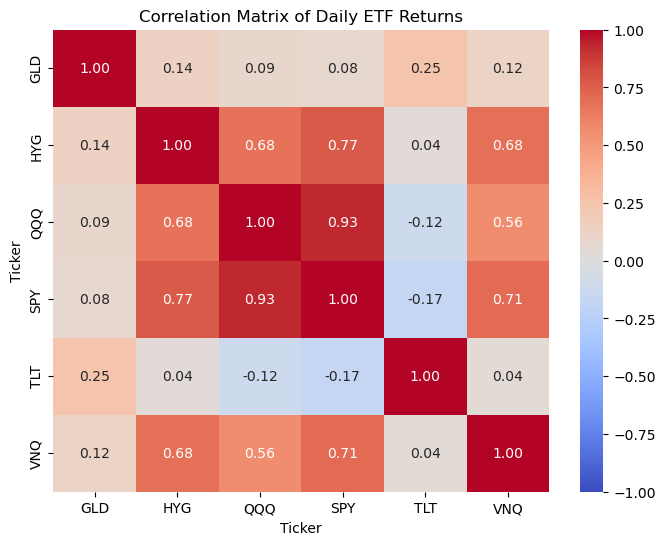

In [134]:
corr_matrix = returns.corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Daily ETF Returns')
plt.show()

### Correlation Analysis Summary
- SPY and QQQ exhibit a very strong positive correlation (0.93), indicating that both ETFs are heavily influenced by broader equity market movements.
- HYG also demonstrates strong positive correlations with equities, suggesting that high-yield bonds may behave similarly to risk assets during periods of market stress.
- TLT is the only asset with a negative correlation to both SPY (-0.17) and QQQ (-0.12), highlighting its potential role as a defensive asset and portfolio hedge.
- GLD maintains relatively low correlations with all other assets, suggesting that gold may provide diversification benefits and respond differently under varying market conditions.

<font size="3"> The varying correlation patterns across asset classes support the use of diversified portfolios and provide evidence that different assets may perform differently across market regimes.

### 5.4 Rolling Volatility Analysis

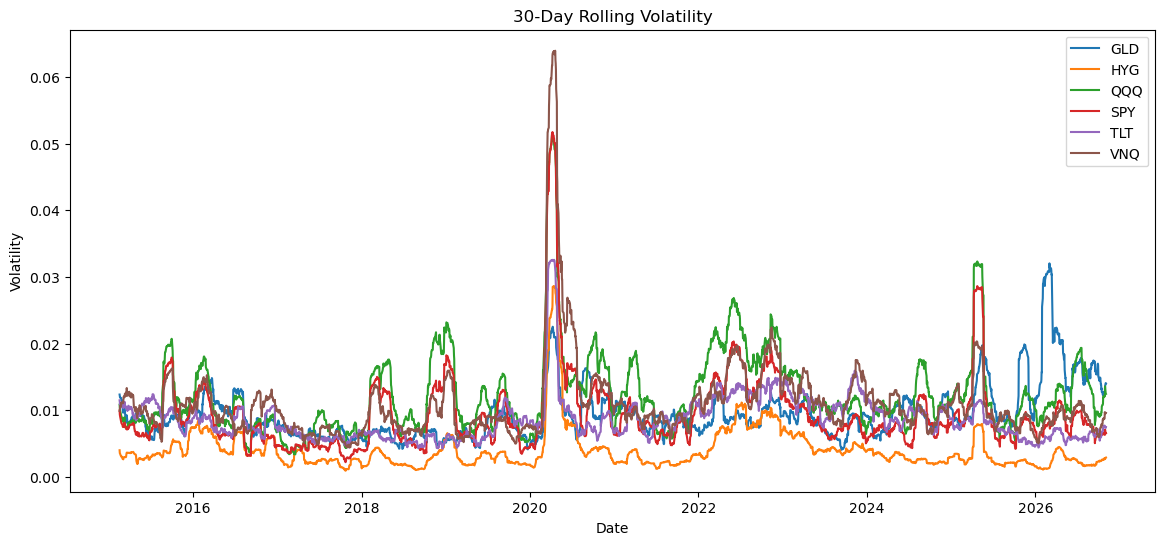

In [124]:
rolling_vol = returns.rolling(window=30).std()

plt.figure(figsize=(14,6))

for col in rolling_vol.columns:
    plt.plot(
        rolling_vol.index,
        rolling_vol[col],
        label=col
    )

plt.title('30-Day Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.legend()
plt.show()

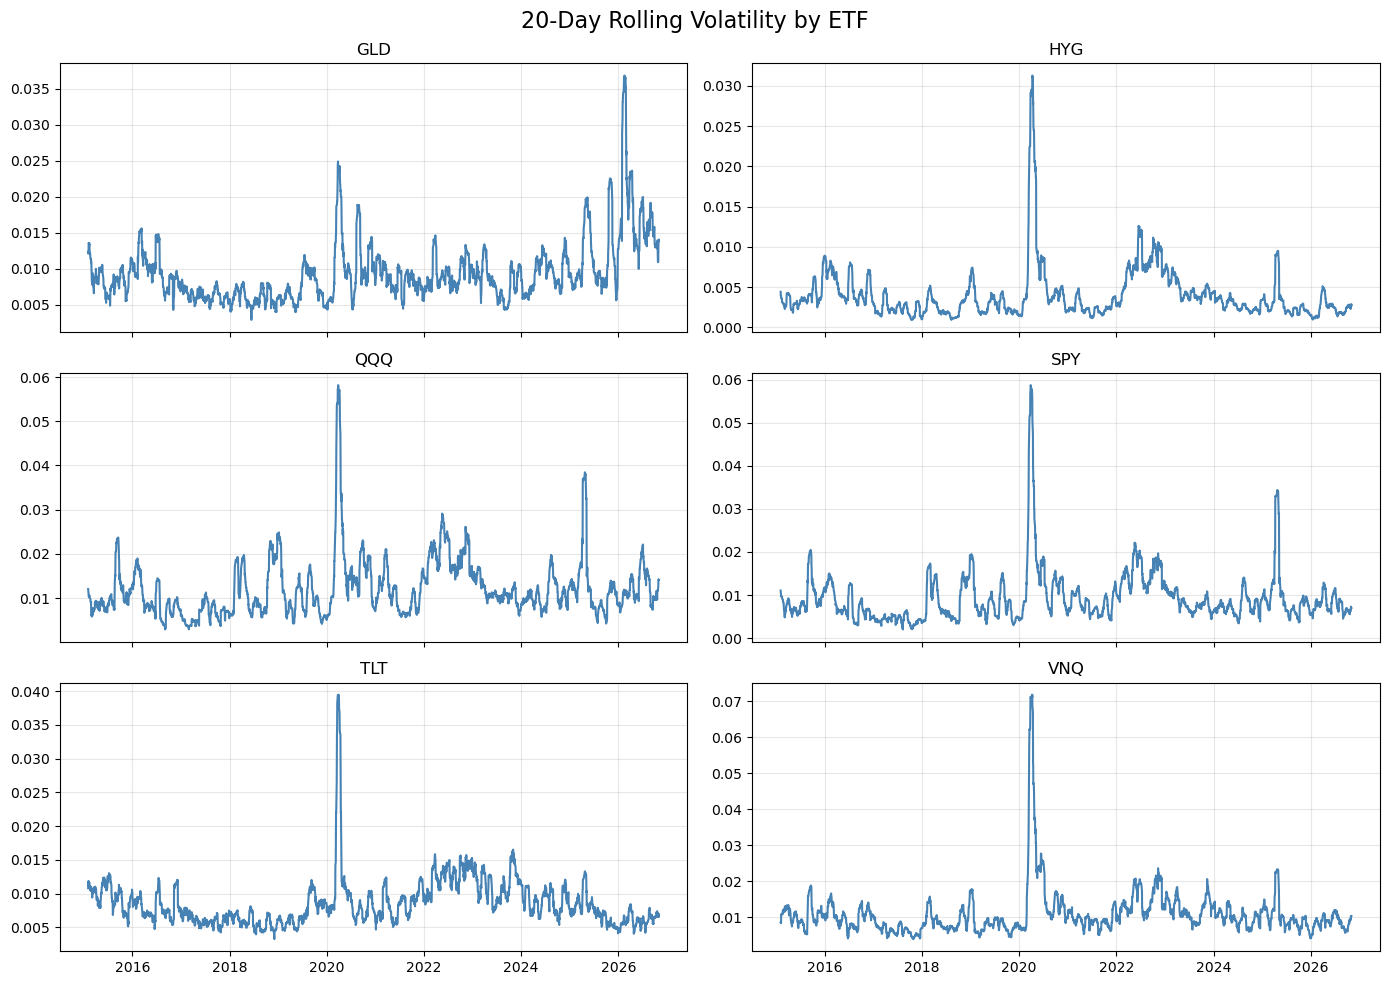

In [125]:
rolling_vol = returns.rolling(20).std()

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14,10),
    sharex=True
)

axes = axes.flatten()

for i, col in enumerate(rolling_vol.columns):
    axes[i].plot(
        rolling_vol.index,
        rolling_vol[col],
        color='steelblue'
    )

    axes[i].set_title(col)
    axes[i].grid(True, alpha=0.3)

plt.suptitle('20-Day Rolling Volatility by ETF', fontsize=16)
plt.tight_layout()
plt.show()

### Rolling Volatility Analysis Summary
- The 20-day rolling volatility analysis revealed substantial variation in risk levels over time across all asset classes.
- A significant and synchronized volatility spike occurred during the COVID-19 market disruption, indicating a distinct high-volatility market regime.
- QQQ consistently exhibited the highest volatility among the assets analyzed, while HYG remained the most stable.
- Treasury bonds (TLT) experienced elevated volatility during the 2022-2023 interest-rate tightening cycle, demonstrating that even traditionally defensive assets can experience periods of increased risk.

<font size="3">  These findings provide strong evidence that market conditions change through time and support the use of regime detection techniques to identify different market environments.

### 5.5 Drawdown Analysis

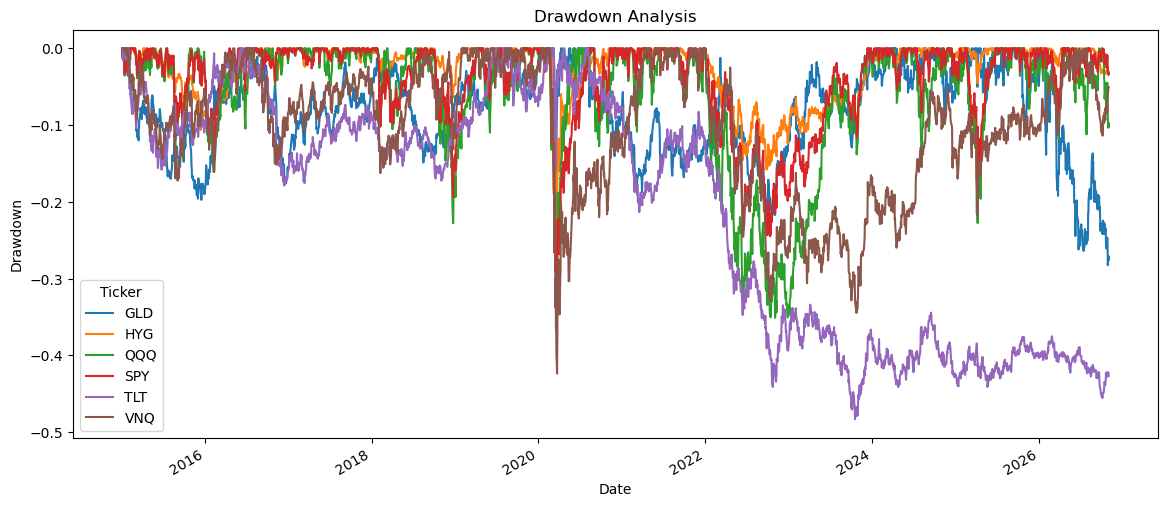

In [126]:
cumulative_returns = (1 + returns).cumprod()

rolling_max = cumulative_returns.cummax()

drawdown = (cumulative_returns - rolling_max) / rolling_max

drawdown.plot(
    figsize=(14,6)
)

plt.title('Drawdown Analysis')
plt.ylabel('Drawdown')
plt.show()

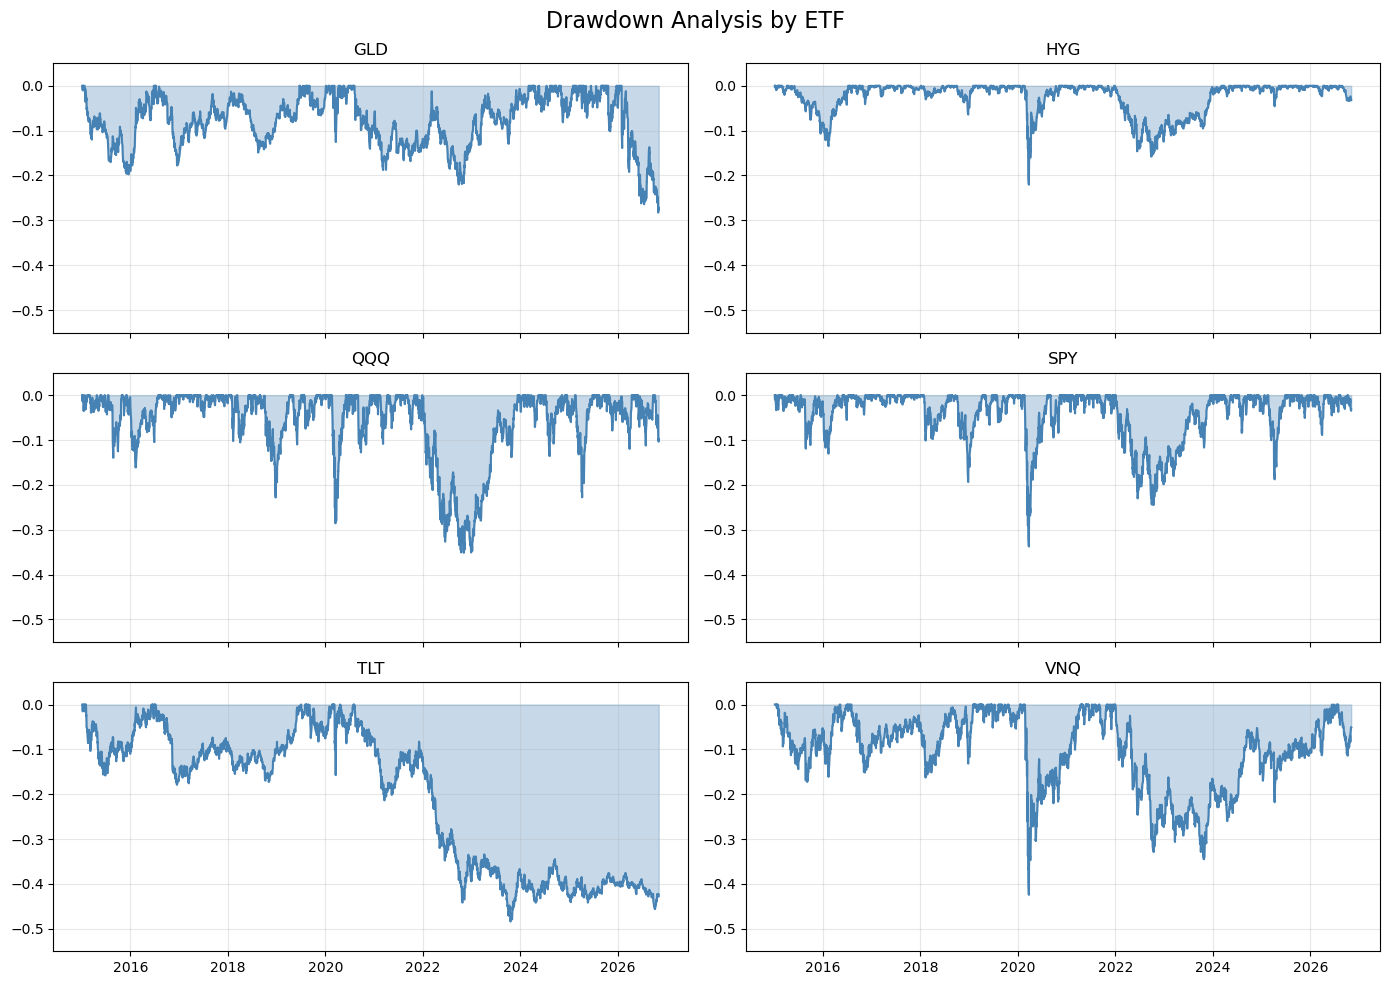

In [127]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(14,10),
    sharex=True
)

axes = axes.flatten()

for i, col in enumerate(drawdown.columns):
    axes[i].plot(
        drawdown.index,
        drawdown[col],
        color='steelblue',
        linewidth=1.5
    )

    axes[i].fill_between(
        drawdown.index,
        drawdown[col],
        0,
        alpha=0.3,
        color='steelblue'
    )

    axes[i].set_title(col)
    axes[i].set_ylim(-0.55, 0.05)
    axes[i].grid(True, alpha=0.3)

plt.suptitle('Drawdown Analysis by ETF', fontsize=16)
plt.tight_layout()
plt.show()

### Drawdown Analysis Summary
- TLT experienced the deepest and most persistent drawdown, reaching nearly 50% below its prior peak and failing to recover during the sample period.
- QQQ and SPY experienced significant drawdowns during market stress events but generally recovered more quickly and frequently established new highs.
- VNQ exhibited prolonged drawdowns during both the COVID-19 crisis and the subsequent rising-rate environment.
- HYG maintained the most stable drawdown profile with relatively shallow losses.
- GLD displayed a unique drawdown pattern that was often independent of equity market movements.
  
 <font size="3"> Drawdown behavior varied substantially across asset classes, highlighting meaningful differences in downside risk.

### 5.6 Distribution Analysis 

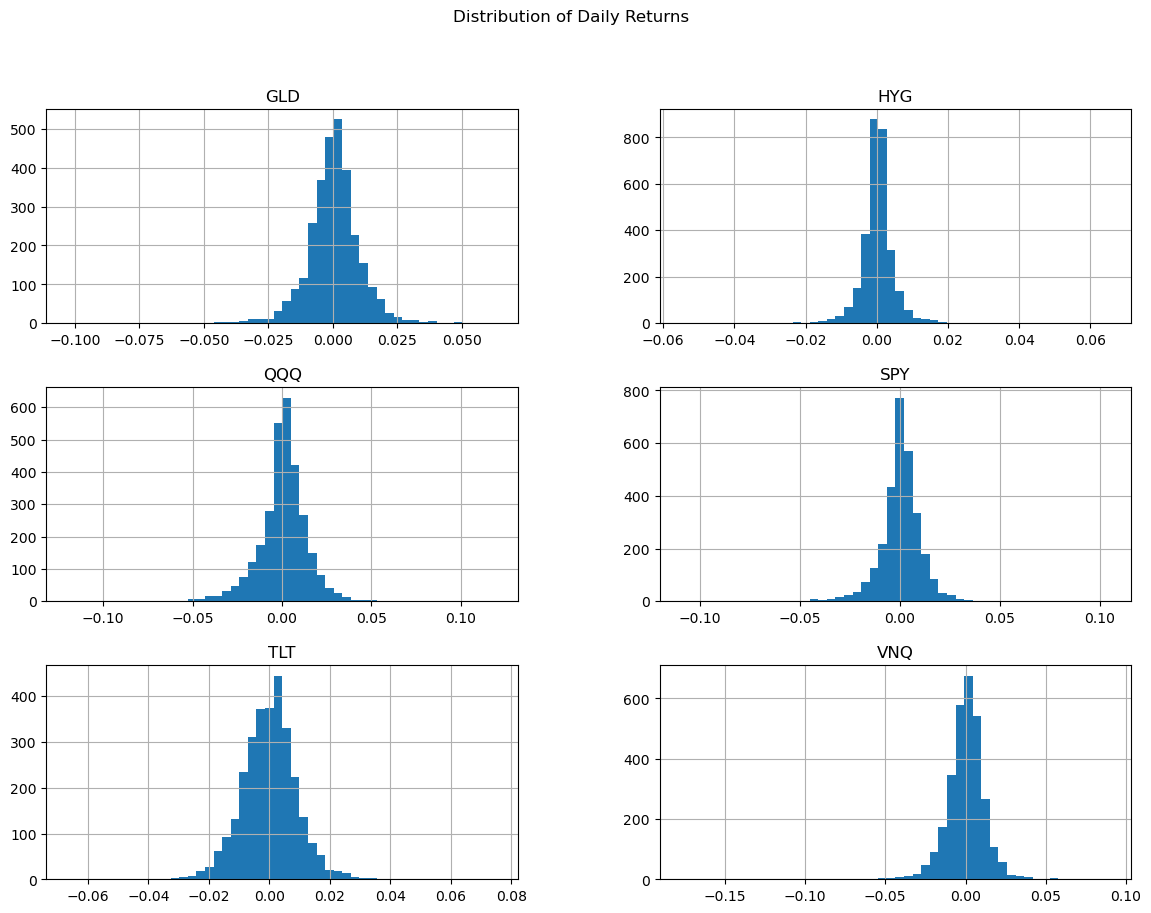

In [128]:
returns.hist(
    figsize=(14,10),
    bins=50
)

plt.suptitle('Distribution of Daily Returns')
plt.show()

### Return Distribution Analysis Summary
- Daily return distributions for all six ETFs are centered near zero, indicating that small daily price movements are most common.
- QQQ exhibits the widest distribution of returns, reflecting its higher volatility and greater sensitivity to changing market conditions.
- HYG demonstrates the most concentrated distribution, suggesting a more stable return profile.

<font size="3">  The differences in return distributions across asset classes provide additional evidence that risk characteristics vary significantly across market environments.

## 6. Feature Enginering
Objective : Transform raw ETF price data into predictive features that capture:
- Momentum
- Volatility
- Trend
- Drawdown

<font size="3"> These features will later be used for machine learning and market regime identification.

<font size="3"> 20-Day Momentum and 50-Day Momentum

In [55]:
momentum_20 = prices.pct_change(20)
momentum_20.columns = [f'{col}_mom20' for col in momentum_20.columns]

momentum_50 = prices.pct_change(50)
momentum_50.columns = [f'{col}_mom50' for col in momentum_50.columns]

print(momentum_20.tail())
print(momentum_50.tail())

            GLD_mom20  HYG_mom20  QQQ_mom20  SPY_mom20  TLT_mom20  VNQ_mom20
Date                                                                        
2026-10-22  -0.057928  -0.005739  -0.049427  -0.004197   0.033357   0.016233
2026-10-23  -0.068122  -0.006000  -0.053862  -0.014753   0.029596   0.018683
2026-10-26  -0.026699   0.000045  -0.033033  -0.000313   0.043106   0.028480
2026-10-27  -0.027710   0.007565  -0.022604   0.007145   0.047664   0.020546
2026-10-28  -0.023816   0.009328  -0.022804   0.010739   0.043850   0.022426
            GLD_mom50  HYG_mom50  QQQ_mom50  SPY_mom50  TLT_mom50  VNQ_mom50
Date                                                                        
2026-10-22  -0.088709  -0.021889  -0.025558  -0.008586   0.003333  -0.039630
2026-10-23  -0.081086  -0.024728  -0.036794  -0.020598  -0.007379  -0.051593
2026-10-26  -0.083840  -0.021849  -0.024796  -0.011682   0.003452  -0.049094
2026-10-27  -0.081901  -0.015546  -0.010781  -0.001422   0.011344  -0.048874

<font size="3"> 20-Day Rolling Volatility and 50-Day Rolling Volatility

In [59]:
volatility_20 = returns.rolling(20).std()
volatility_20.columns = [f'{col}_vol20' for col in volatility_20.columns]

volatility_50 = returns.rolling(50).std()
volatility_50.columns = [f'{col}_vol50' for col in volatility_50.columns]

print(volatility_20.tail())
print(volatility_50.tail())


            GLD_vol20  HYG_vol20  QQQ_vol20  SPY_vol20  TLT_vol20  VNQ_vol20
Date                                                                        
2026-10-22   0.013891   0.002286   0.011683   0.006194   0.007058   0.009352
2026-10-23   0.013804   0.002287   0.011581   0.006143   0.007183   0.009330
2026-10-26   0.010956   0.002153   0.011810   0.006167   0.006778   0.009285
2026-10-27   0.010885   0.002369   0.012219   0.006273   0.006606   0.009534
2026-10-28   0.010845   0.002310   0.012216   0.006251   0.006884   0.009432
            GLD_vol50  HYG_vol50  QQQ_vol50  SPY_vol50  TLT_vol50  VNQ_vol50
Date                                                                        
2026-10-22   0.014819   0.002251   0.010583   0.006148   0.007215   0.008044
2026-10-23   0.014717   0.002217   0.010440   0.006101   0.007200   0.007796
2026-10-26   0.014690   0.002242   0.010572   0.006188   0.007162   0.007829
2026-10-27   0.014728   0.002375   0.010732   0.006206   0.007058   0.007825

<font size="3"> Moving Average Trend Features

In [62]:
ma20 = prices.rolling(20).mean()
ma50 = prices.rolling(50).mean()

ma_ratio = ma20 / ma50

ma_ratio.columns = [f'{col}_ma_ratio' for col in ma_ratio.columns]

ma_ratio.tail()

,GLD_ma_ratio,HYG_ma_ratio,QQQ_ma_ratio,SPY_ma_ratio,TLT_ma_ratio,VNQ_ma_ratio
Date,,,,,,
2026-10-22,0.962752,0.988088,1.015512,1.004564,0.979226,0.970010
2026-10-23,0.960935,0.988285,1.013502,1.004241,0.980830,0.971970
2026-10-26,0.961296,0.988724,1.012330,1.004462,0.982863,0.974359
2026-10-27,0.961571,0.989410,1.011399,1.004847,0.984952,0.976352
2026-10-28,0.961728,0.990165,1.010065,1.005243,0.987106,0.978512


<font size="3"> Drawdown Features

In [72]:
# we have already calculated Drawdown
drawdown.columns = [f'{col}_drawdown' for col in drawdown.columns]

drawdown.head()

,GLD_drawdown,HYG_drawdown,QQQ_drawdown,SPY_drawdown,TLT_drawdown,VNQ_drawdown
Date,,,,,,
2015-01-05,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
2015-01-06,0.000000,-0.00383,-0.013408,-0.009419,0.000000,0.0
2015-01-07,-0.005891,0.00000,-0.000690,0.000000,-0.001975,0.0
2015-01-08,-0.010075,0.00000,0.000000,0.000000,-0.015192,0.0
2015-01-09,0.000000,0.00000,-0.006583,-0.008014,-0.004406,0.0


In [73]:
features = pd.concat([
    momentum_20,
    momentum_50,
    volatility_20,
    volatility_50,
    ma_ratio,
    drawdown
], axis=1)
features.shape

(2973, 36)

In [76]:
features.head()

,GLD_mom20,HYG_mom20,QQQ_mom20,SPY_mom20,TLT_mom20,VNQ_mom20,GLD_mom50,HYG_mom50,QQQ_mom50,SPY_mom50,...,QQQ_ma_ratio,SPY_ma_ratio,TLT_ma_ratio,VNQ_ma_ratio,GLD_drawdown,HYG_drawdown,QQQ_drawdown,SPY_drawdown,TLT_drawdown,VNQ_drawdown
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,0.000000,0.000000,0.0
2015-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000000,-0.00383,-0.013408,-0.009419,0.000000,0.0
2015-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.005891,0.00000,-0.000690,0.000000,-0.001975,0.0
2015-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,-0.010075,0.00000,0.000000,0.000000,-0.015192,0.0


In [77]:
features = features.dropna()

In [80]:
print(features.shape)
features.isnull().sum().sum()

(2923, 36)


np.int64(0)

In [87]:
features.describe().T.head(5)

,count,mean,std,min,25%,50%,75%,max
GLD_mom20,2923.0,0.009159,0.043606,-0.160928,-0.018114,0.005165,0.035223,0.243200
HYG_mom20,2923.0,0.003355,0.021703,-0.211096,-0.005144,0.004847,0.012570,0.150839
QQQ_mom20,2923.0,0.015263,0.053880,-0.278469,-0.012485,0.019444,0.047749,0.254054
SPY_mom20,2923.0,0.011255,0.043193,-0.309867,-0.007915,0.016277,0.034916,0.230725
TLT_mom20,2923.0,-0.000308,0.037196,-0.116439,-0.023727,-0.001318,0.023105,0.187723


## Summary

- 20-Day Momentum : Measures short-term price trend
- 50-Day Momentum : Measures medium-term price trend
- 20-Day Volatility : Measures short-term market risk
- 50-Day Volatility : Measures medium-term risk
- Moving Average Ratio : Captures bullish/bearish trend conditions
- Drawdown : Measures decline from previous peak

F<font size="3">eature engineering was performed to transform raw ETF price data into variables that better describe market behavior. A total of 36 features were generated, including Momentum indicators (20-day and 50-day returns), rolling volatility measures, moving average ratios, and drawdown metrics were created for each ETF. These engineered variables were designed to capture trend, risk, and market stress conditions and will serve as inputs for the baseline machine learning model and subsequent market regime detection analysis.

## 7. Baseline Machine Learning Model

### Create the Target Variable


<font size="3">Future 20-day volatility of SPY

In [88]:
future_volatility = (
    returns['SPY']
    .rolling(20)
    .std()
    .shift(-20)
)

In [89]:
target = (
    future_volatility >
    future_volatility.median()
).astype(int)

In [90]:
model_data = pd.concat(
    [features, target.rename('target')],
    axis=1
).dropna()

In [92]:
print(model_data.shape)
model_data['target'].value_counts()

(2923, 37)


target
0    1478
1    1445
Name: count, dtype: int64

<font size="3"> To support the development of a baseline machine learning model, a binary target variable was created using future 20-day volatility of the SPY ETF. Observations with future volatility above the median value were classified as a high-volatility regime (1), while observations below the median were classified as a low-volatility regime (0). This approach resulted in a nearly balanced target distribution, making it suitable for classification modeling and evaluation.

### Build the Baseline Model 

In [93]:
X = model_data.drop('target', axis=1)
y = model_data['target']

print(X.shape)
y.value_counts()

(2923, 36)


target
0    1478
1    1445
Name: count, dtype: int64

Because this is financial time-series data we will be using chronological split

In [94]:
split_idx = int(len(model_data) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print(X_train.shape)
print(X_test.shape)

(2338, 36)
(585, 36)


<font size="3"> Train Random Forest

In [135]:

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

In [96]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.505982905982906

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.57      0.52       276
           1       0.54      0.45      0.49       309

    accuracy                           0.51       585
   macro avg       0.51      0.51      0.51       585
weighted avg       0.51      0.51      0.50       585


Confusion Matrix:
[[156 120]
 [169 140]]


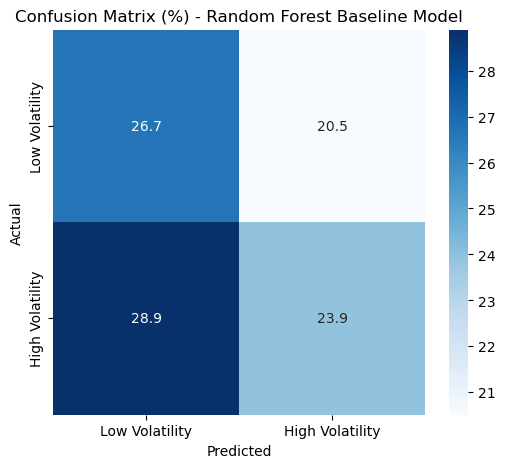

In [97]:
cm = confusion_matrix(y_test, y_pred)

cm_pct = cm / cm.sum() * 100

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    xticklabels=['Low Volatility', 'High Volatility'],
    yticklabels=['Low Volatility', 'High Volatility']
)

plt.title('Confusion Matrix (%) - Random Forest Baseline Model')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

### Baseline Model Results

A Random Forest classifier was developed as a baseline model to predict future market volatility regimes using engineered momentum, volatility, trend, and drawdown features. The model achieved an overall accuracy of approximately 50.6%, with F1-scores of 0.52 and 0.49 for the low-volatility and high-volatility classes, respectively. While the model exhibited balanced performance across both classes, predictive accuracy remained close to the level of random classification.

The confusion matrix shows that the baseline Random Forest model achieved only modest performance (50.6% accuracy), indicating that additional feature engineering and more advanced modeling techniques are needed to improve volatility regime classification.

### Interpretation

These results suggest that the initial feature set provides limited predictive power for forecasting future volatility regimes. Market regime dynamics are likely influenced by more complex relationships than can be captured by the baseline model. Consequently, additional feature engineering, dimensionality reduction techniques, regime identification methods, and model optimization will be explored in Capstone project.


## 8. Conclusion and Next Steps

<font size="3">  The exploratory data analysis revealed meaningful differences in return, risk, correlation, volatility, and drawdown characteristics across asset classes, providing evidence of changing market conditions over time. The baseline Random Forest model achieved an accuracy of 50.6%, indicating limited predictive power for future volatility regimes but establishing a benchmark for comparison. These findings support the project's hypothesis that market environments evolve over time and motivate further investigation into market regime detection and machine learning-driven dynamic asset allocation strategies.Future work will focus on applying market regime detection techniques, enhancing feature engineering, and evaluating advanced machine learning models to determine whether dynamic asset allocation strategies can improve risk-adjusted portfolio performance.